# Transport of a Pollutant in a River

## Introduction

A quantity of a pollutant has entered a river. At time $t=0$, its concentration profile is block-shaped, with a length of 10 km and a maximum concentration of 10 mg/$m^{3}$. For the river section, we have the following data: the average flow velocity is $u = 0.5$ m/s, and the diffusion coefficient is $K = 100$ $m^{2}/s$.

The objective of this assignment is to determine when the maximum concentration passes a point located 60 km downstream from the point where the pollutant was present at $t=0$. We shall refer to these two locations as B and A, respectively. Furthermore, we aim to determine the value of the maximum concentration at point B.

You are provided with the Python script containing the code for the solution of the following 1D advection-diffusion equation:

$$
  \frac{\partial c}{\partial t} + u \frac{\partial c}{\partial x} - K\frac{\partial^2 c}{\partial x^2} = 0\, , \quad x \in [0,L]
$$

where $c(x,t)$ is the concentration (in mg/$m^{3}$) and $L$ is the length of the river section (in meters). This equation describes the transport of the cloud of pollutant along the river at a constant speed while spreading in the river as time proceeds.

For the simulations and the analysis that we will carry out, the following step sizes will be used as baseline: $\Delta x = 0.4$ km and $\Delta t = 10$ minutes.

## Part I: find the solution

>**Task 1.1**
>
>Before we proceed with simulating the transport of the cloud of pollutant, we will first answer a few questions to get an idea of the problem.
>
>1. How long does it take for the peak of the cloud to pass point B?
>2. What will the profile of the cloud look like at point B and what is its maximum length? You may provide a schematic drawing.
>3. What will the maximum concentration in B be?
>
>To answer the questions above, you may use the exact solution for the **diffusion** equation ($u=0$) with a block-shaped initial cloud that is centered around $x=0$. This solution is given as:
>
>$$
>  c(x,t) = \frac{c_0}{2} \left [ \text{erf} \left ( \frac{0.5L_c-x}{2\sqrt{Kt}} \right ) + \text{erf} \left ( \frac{0.5L_c+x}{2\sqrt{Kt}} \right ) \right ]
>$$
>
>with $c_0$ the initial concentration and $L_c$ the initial cloud length.
>
> **Hint:** Use the exact solution for diffusion considering that the advection term does not change the level of the maximum concentration for given $t$. Think about at which $x$ the diffusion solution will have its maximum. You can evaluate the error function $\text{erf}(z)$ with `scipy.special.erf`.


**Answer Task 1.1**

**Assumptions**

1. The flow velocity $u = 0.5$ m/s and the diffusion coefficient $K = 100$ m$^2$/s are constant in space and time (uniform river section, no tributaries, no change in cross-section).
2. The problem is 1D: the pollutant is fully mixed over the width and depth of the river, so $c$ only depends on $x$ and $t$.
3. The pollutant is conservative: no decay, no settling, no reactions, and no inflow or outflow of pollutant. The total mass $c_0 L_c$ per unit cross-section stays the same.
4. The river is long enough that the boundaries do not affect the cloud (an infinite domain). This is needed for the exact erf-solution to be valid.
5. Point A is the **centre** of the block-shaped cloud at $t=0$. Point B is 60 km downstream of this centre.
6. Advection and diffusion can be split. Since $u$ is constant, the solution of the advection-diffusion equation is just the diffusion solution moved along with the flow:
$$c_{\text{adv-diff}}(x,t) = c_{\text{diff}}(x - ut,\,t)$$
So advection only **moves** the cloud. It does not change its shape or its maximum concentration (this is the hint). Diffusion only **spreads** the cloud. It does not move its centre.

**1. When does the peak pass point B?**

The diffusion solution is symmetric around $x=0$, so it is largest at the centre of the cloud. Diffusion does not move this centre. The peak therefore moves downstream with exactly the flow velocity $u$:
$$t_B = \frac{\Delta x_{AB}}{u} = \frac{60\,000\ \text{m}}{0.5\ \text{m/s}} = 120\,000\ \text{s} \approx 33.3\ \text{h} \approx 1.39\ \text{days}$$

**2. Profile of the cloud at B and its length**

At $t=0$ the profile is a block (10 mg/m$^3$ over 10 km) with sharp edges. Diffusion smooths the sharp edges right away, and over time the cloud becomes a symmetric, **bell-shaped (almost Gaussian) profile** that is lower and wider. The area under the curve (the mass) does not change (assumption 3).

The typical diffusion length scale at $t_B$ is
$$\sqrt{K t_B} = \sqrt{100 \cdot 120\,000} \approx 3.46\ \text{km}, \qquad 2\sqrt{Kt_B} \approx 6.9\ \text{km}$$
This is of the same order as the initial half-length of 5 km. So the block shape has disappeared and the profile looks like a Gaussian.

A bell curve has no sharp edges in theory (the concentration is $>0$ everywhere). So the "length" of the cloud depends on the cut-off we choose. One way to estimate it is with the variance of the cloud. The variance of the initial block, $L_c^2/12$, plus the growth from diffusion, $2Kt$, gives:
$$\sigma^2 = \frac{L_c^2}{12} + 2Kt_B = 8.3\cdot10^6 + 2.4\cdot10^7 \;\Rightarrow\; \sigma \approx 5.7\ \text{km}$$
About 99.7% of the mass lies within $\pm 3\sigma$, so the cloud length at B is roughly
$$L_{\text{cloud}} \approx 6\sigma \approx 34\ \text{km}$$
If we evaluate the exact erf-solution, we get the same result. The cloud is about **33 km** long if we take 1% of $c_0$ (0.1 mg/m$^3$) as the edge, and about 40 km if we take 0.01 mg/m$^3$ as the edge. The cloud grows from 10 km to roughly **35 km** (this is the maximum length when it passes B).

**How long does it take for the cloud to pass B?**

The cloud moves past B with the flow velocity $u = 0.5$ m/s. It is about 35 km long, so the time between the front and the tail passing B is
$$t_{\text{pass}} = \frac{L_{\text{cloud}}}{u} \approx \frac{35\,000\ \text{m}}{0.5\ \text{m/s}} = 70\,000\ \text{s} \approx 19\ \text{h}$$
The peak is in the middle of the cloud. The front therefore reaches B about half of this time earlier, $\approx 9$–$10$ h before the peak ($t \approx 24$ h). The tail leaves B about 9–10 h after the peak ($t \approx 43$ h). Because the cloud also keeps spreading while it passes B, the tail is slightly longer than the front. This effect is small, so we ignore it in this estimate.


Schematic drawing (concentration against distance):

```
c [mg/m3]
 10 |   ______                                      t = 0 (block, 10 km)
    |  |      |
  7 |  |      |                      .-"""-.        t = t_B (bell, peak ~6.9)
    |  |      |                   .-'       '-.
    |  |      |                .-'             '-.
  0 |__|______|___________..--'_________|_________'--..______  x
       A (centre, x = 0)                B (x = 60 km)
                                  |<----- ~ 35 km ----->|
```

**3. Maximum concentration at B**

The diffusion solution is maximal at the centre of the cloud ($x = 0$ in the moving frame). At that point both erf terms are the same:
$$c_{\max}(t) = \frac{c_0}{2}\left[\text{erf}\left(\frac{0.5L_c}{2\sqrt{Kt}}\right) + \text{erf}\left(\frac{0.5L_c}{2\sqrt{Kt}}\right)\right] = c_0\,\text{erf}\left(\frac{L_c}{4\sqrt{Kt}}\right)$$
Advection does not change this maximum (assumption 6). So at $t = t_B = 120\,000$ s:
$$c_{\max,B} = 10 \cdot \text{erf}\left(\frac{10\,000}{4\cdot 3464}\right) = 10\cdot\text{erf}(0.722) \approx 10 \cdot 0.693 \approx \mathbf{6.9\ mg/m^3}$$

So when the peak passes B, the maximum concentration has dropped from 10 to about 6.9 mg/m$^3$ (about 31% lower). The mass is the same, but it is spread over a much longer part of the river. The numerical results in Task 1.3 should give the same arrival time and peak value, apart from small discretisation errors.

---
**Courant and mesh Péclet number**
$$\sigma = \frac{u\,\Delta t}{\Delta x}, \qquad Pe_{\Delta x} = \frac{u\,\Delta x}{K}$$
The exact solution does not use a grid. For the baseline grid ($u = 0.5$ m/s, $K = 100$ m$^2$/s, $\Delta x = 400$ m, $\Delta t = 600$ s):
$$\sigma = \frac{0.5\cdot600}{400} = 0.75, \qquad Pe_{\Delta x} = \frac{0.5\cdot400}{100} = 2$$


### Python module for numerical solution to advection-diffusion equation

Here we outline the usage of the Python module `advdiff.py` in this folder, which contains the solver for the above presented advection-diffusion equation.

An initial condition $c(x,0) = c0(x)$ must be provided by the user such that $c0(0) = c0(L) = 0$, so that no boundary conditions need to be imposed.

**An important note here: choose $L$ such that the entire profile of the cloud transported along the river is completely visible in the plot.**

The use of function `advdiff` is as follows:

```
c = advdiff ( u, K, c0, L, dt, T, dxmethod, dtmethod, theta )
```

and the input parameters are defined as follows:
- `u` = flow velocity (in m/s)
- `K` = diffusion coefficient (in m$^{2}$/s)
- `c0` = initial condition (row vector)
- `L` = length of computational domain (in m)
- `dt` = time step (in s)
- `T` = simulation end time (in s)
- `dxmethod` = spatial discretization scheme
- `dtmethod` = time integration scheme
- `theta` = implicitness parameter ($0 \leq $ `theta` $\leq 1$)

The output parameter is `c` which contains the numerical solution of the advection-diffusion equation.
This variable is a 2D array `c[0:N,0:M]` with `N` the number of time steps and `M` the number of grid cells.
The grid is equidistant so that the grid points are uniformly distributed with a constant grid size $\Delta x = L/$`M`.

The row vector `c0` represents the initial value of $c(x,0)$ at uniformly spaced points in $[0,L]$.
Hence, the dimension of this vector is `c0[0:M]`.
Note that `c0` is a grid function and thus indirectly defines the computational grid. (The script therefore calculates the value of $\Delta x$ itself.)

The allowed values of `dxmethod` in this assignment are:
- `central` = second order central differences
- `upwind` = first order upwind scheme

These two methods only concern the advection term while the diffusion term is approximated exclusively with central differences.

The relevant value of `dtmethod` in this assignment is `'theta'` and represents the $\theta$-method, to be discussed in the following part.

The last argument of `advdiff` specifies the actual value of the implicitness parameter $\theta$. Special cases are
- `theta = 0.0` is forward Euler
- `theta = 0.5` is Crank-Nicolson
- `theta = 1.0` is backward Euler

**The code in the `.py` file is complete and does not need to be modified.**

Import `advdiff` in the cell below.

In [4]:
from advdiff import advdiff

>**Task 1.2**
>
>In the next cell, we specify the initial condition `c0` of the cloud of pollutant which has a *block-shaped* profile with a length of 10 km.
>Note that the maximum concentration value is 10 $mg/m^{3}$.
>For the computational domain, we must choose a length that visualizes the propagation of the bell-curve, including its head and tail, through the domain all the way. Make an estimate of this length.
>
>Fill in the missing domain length and run the cell below to plot the initial condition.
>


Text(0, 0.5, 'concentration [mg/m3]')

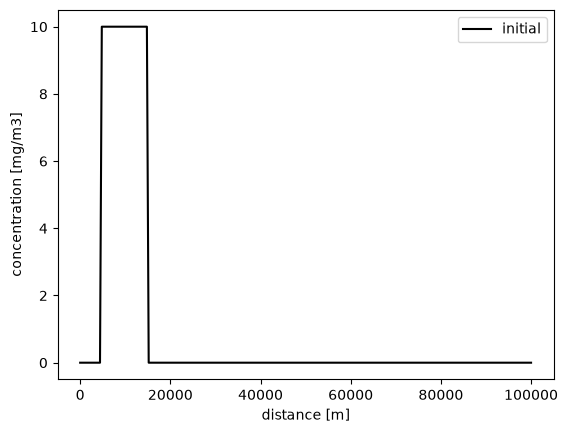

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# domain length
lenD = 100000.           # 100 km: cloud centre at 10 km + 60 km travel + ~20 km half-length + margin

lenC = 10000.             # length of c0
dx = 400.                 # grid size

M = int(lenD/dx) + 1      # number of grid points
x = np.linspace(0,lenD,M) # array with coordinates of grid points

# initial condition
c0 = np.zeros(M)
c0[int(0.5 * lenC/dx):int(0.5 * lenC/dx) + int(lenC/dx) + 1] = 10.
plt.plot(x,c0,'k',label='initial')
plt.legend(loc='upper right')
plt.xlabel('distance [m]')
plt.ylabel('concentration [mg/m3]')

**Answer Task 1.2: estimate of the domain length**

The domain has to contain the whole cloud during the whole simulation. The worst moment is at the end, when the cloud has moved furthest and is widest.

- **Start position:** in the code, the block lies between $x = 0.5L_c = 5$ km and $x = 15$ km. Its centre (point A) is at $x = 10$ km. The left part of the domain ($0$–$5$ km) gives room for the diffusion of the upstream edge, so $c_0(0) = 0$.
- **Travel distance:** the simulation runs until the peak passes B, at $t_B = 120\,000$ s. In that time the centre moves $u\,t_B = 60$ km, so it ends at $x = 10 + 60 = 70$ km (point B).
- **Width at B:** from Task 1.1 the cloud is about 35–40 km long at B (bell shape, $\sigma \approx 5.7$ km). Half of that, about 20 km, lies downstream of the peak. So the head of the cloud reaches about $70 + 20 = 90$ km.
- **Margin:** we add about 10 km of margin. Then the concentration at the right boundary is practically zero, $c(L) \approx 0$. This is needed because the solver does not impose boundary conditions.

$$L = 10 + 60 + 20 + 10 \approx 100\ \text{km} = 100\,000\ \text{m}$$

With $\Delta x = 400$ m this gives $M = 100\,000/400 + 1 = 251$ grid points.

---
**Courant and mesh Péclet number**
$$\sigma = \frac{u\,\Delta t}{\Delta x}, \qquad Pe_{\Delta x} = \frac{u\,\Delta x}{K}$$
With $u = 0.5$ m/s, $K = 100$ m$^2$/s, $\Delta x = 400$ m and $\Delta t = 600$ s:
$$\sigma = \frac{0.5\cdot600}{400} = 0.75, \qquad Pe_{\Delta x} = \frac{0.5\cdot400}{100} = 2$$


>**Task 1.3**
>
>We will now run the simulation using the script above. Enter the required data in the fields below and run the cell.


In [6]:
# parameters for advdiff

u = 0.5                   # flow velocity [m/s]
K = 100.                  # diffusion coefficient [m2/s]
dt = 10*60.               # time step: 10 min = 600 s
Tend = 60000./u           # time for the peak to travel 60 km (A -> B) = 120000 s


# compute solution to transport equation
c=advdiff(u,K,c0,lenD,dt,Tend,'central','theta',0.5)

The cell below creates a plot of the solution at final time step. Here, `N` represents the number of time steps. Enter a value for `N` and generate the plot.

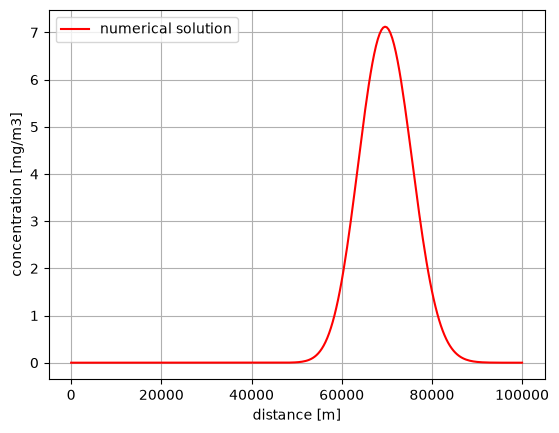

In [7]:
# number of timesteps
N = int(Tend/dt)          # = 200; c has N+1 rows (row 0 = initial condition), so c[N,:] is the solution at t = Tend

plt.plot(x,c[N,:],'r',label='numerical solution')
plt.legend(loc='upper left')
plt.xlabel('distance [m]')
plt.ylabel('concentration [mg/m3]')
plt.grid()

**Task 1.3: result**

The numerical solution at $t = 120\,000$ s has its peak at $x \approx 70$ km (point B), with $c_{\max} = 7.12$ mg/m$^3$. This matches Task 1.1 (6.93 mg/m$^3$). The small difference comes from the block on the grid being 10.4 km long instead of 10 km: $10\,\text{erf}(10.4/13.86) = 7.12$ mg/m$^3$.

---
**Courant and mesh Péclet number**
$$\sigma = \frac{u\,\Delta t}{\Delta x}, \qquad Pe_{\Delta x} = \frac{u\,\Delta x}{K}$$
With $u = 0.5$ m/s, $K = 100$ m$^2$/s, $\Delta x = 400$ m and $\Delta t = 600$ s:
$$\sigma = \frac{0.5\cdot600}{400} = 0.75, \qquad Pe_{\Delta x} = \frac{0.5\cdot400}{100} = 2$$


Compare the numerical solution with your answers from **Task 1.1**.

>**Task 1.4**
>
>What are the Courant and mesh P&eacute;clet numbers?


**Answer Task 1.4**

We use the parameters of the run in Task 1.3: $u = 0.5$ m/s, $K = 100$ m$^2$/s, $\Delta x = 400$ m and $\Delta t = 600$ s (10 min).

**Courant number**

The Courant number is the number of grid cells the flow moves in one time step:
$$\sigma = \frac{u\,\Delta t}{\Delta x} = \frac{0.5 \cdot 600}{400} = \mathbf{0.75}$$
So in one time step the cloud moves 300 m, which is less than one grid cell. This number matters for the stability of explicit schemes. For example, explicit upwind needs $\sigma \leq 1$. We use Crank-Nicolson ($\theta = 0.5$), which is unconditionally stable, so for this run $\sigma$ mainly affects the accuracy and not the stability.

**Mesh Péclet number**

The mesh Péclet number compares advection with diffusion over the size of one grid cell:
$$Pe_{\Delta x} = \frac{u\,\Delta x}{K} = \frac{0.5 \cdot 400}{100} = \mathbf{2}$$
This is exactly the critical value for central differences in space. The second-order central scheme for advection only gives a solution without spurious oscillations ("wiggles") if $Pe_{\Delta x} \leq 2$. If $Pe_{\Delta x} > 2$, advection dominates within one grid cell, the coefficients of the discrete scheme become negative and the solution can start to oscillate. With $Pe_{\Delta x} = 2$ we are just on the limit, so the central scheme should still give a smooth solution. The grid should not be made coarser (or $K$ smaller) without risking wiggles.

**Extra: diffusion number**

For completeness, the diffusion number is
$$d = \frac{K\,\Delta t}{\Delta x^2} = \frac{100 \cdot 600}{400^2} = 0.375$$
This would matter for explicit time integration (forward Euler with central differences needs $d \leq 0.5$). With Crank-Nicolson it does not limit stability.

---
**Courant and mesh Péclet number**
$$\sigma = \frac{u\,\Delta t}{\Delta x}, \qquad Pe_{\Delta x} = \frac{u\,\Delta x}{K}$$
| $u$ [m/s] | $K$ [m$^2$/s] | $\Delta x$ [m] | $\Delta t$ [s] | $\sigma$ | $Pe_{\Delta x}$ |
|---|---|---|---|---|---|
| 0.5 | 100 | 400 | 600 | 0.75 | 2 |


## Part II: accuracy

### Time integration using the $\theta$-method

During the course you were introduced to the following two time integration methods, namely
- the forward Euler scheme and
- the backward Euler scheme.

Each of these methods has its advantages and disadvantages. Basically, the forward Euler is conditionally stable
while the backward Euler is unconditionally stable. On the other hand, the former is simple to implement and also
cheap in terms of function evaluations while the latter usually results into a system of equations that need
to be solved.
Both methods, however, are first order accurate in time, which could potentially be a disadvantage in many applications.
Now let us take a look at how we can improve this.

Consider the following first order ODE

$$
  \frac{dy}{dt} = f(y)
$$

where we seek for a solution $y(t)$ in the range $0 \leq t \leq T_{\text{end}}$.
This time frame is discretized into a number of steps with a step size of $\Delta t$:
$\{t_n = n\Delta t \,\,|\,\, n = 0, 1, 2, \cdots\}$.
Then, the **forward (explicit) Euler scheme** is given by

$$
  \frac{y^{n+1}-y^n}{\Delta t} = f(y^n)
$$

while the **backward (implicit) Euler scheme** reads

$$
  \frac{y^{n+1}-y^n}{\Delta t} = f(y^{n+1})
$$

Again, both schemes have a truncation error of $\tau_{\Delta t} = \mathcal{O}(\Delta t)$.

If we take the average of the forward and backward Euler schemes, we get

$$
  \frac{y^{n+1}-y^n}{\Delta t} = \frac 12 f(y^n) + \frac 12 f(y^{n+1})
$$

which is known as the **Crank-Nicolson scheme** or the **trapezoidal rule**.
Since the last term of the right-hand side needs to be evaluated based on the solution at the next time step $y^{n+1}$,
the Crank-Nicolson scheme is regarded as *implicit*. Like the backward Euler, this scheme has the disadvantage of the required
system of equations to be solved, but has the advantageous property of unconditional stability.

The reason behind averaging the forward and backward Euler schemes is to improve the accuracy of the resulting scheme.
Indeed, the truncation error of the Crank-Nicolson scheme is given as $\tau_{\Delta t} = \mathcal{O}(\Delta t^2)$.

All the three mentioned schemes above can be generalized to an arbitrary weighted average of $f(y^n)$ and $f(y^{n+1})$, as follows

$$
  \frac{y^{n+1}-y^n}{\Delta t} = \theta\, f(y^{n+1}) + \left ( 1 - \theta \right ) \,f(y^n) 
$$

with $0 \leq \theta \leq 1$ a weight parameter to be chosen. This scheme is called the $\theta$-method
and is explicit if $\theta = 0$ and implicit if $0 < \theta \leq 1$. The parameter $\theta$ is called the
**implicitness parameter** (last argument of the above script). In practice, we will be almost exclusively interested in either
- forward Euler ($\theta = 0$) or
- backward Euler ($\theta = 1$) or
- Crank-Nicolson ($\theta = 1/2$)

In the remainder of this assignment we will work with these three schemes.

>**Task 2.1**
>
>
>
>The goal of this assignment is to determine whether the explicit and implict Euler methods are indeed less accurate than the trapezoidal rule. To this end, first:
> - repeat the previous calculation using a time step of 10 minutes, followed by a calculation with a time step of 5 minutes. 
> 
> Keep central differences for the spatial discretization. Compare both plots and write down your conclusions based on this comparison.
>
>Next: 
> - Perform the calculation again using the last time step, but this time apply the explicit Euler method instead of the trapezoidal rule. 
> - Continue halving the time step until there is no longer any discernible difference between the results of the last two calculations.
> - Repeat the same procedure but for the implicit Euler method. Include your graph and the observed time.
>
>Compare your result with that of the trapezoidal rule and explicit Euler.
>
>Explain your findings based on the notion of *order of accuracy*.


peak CN, dt = 10 min: 7.1219 mg/m3
peak CN, dt =  5 min: 7.1188 mg/m3
max |difference|    : 0.0160 mg/m3


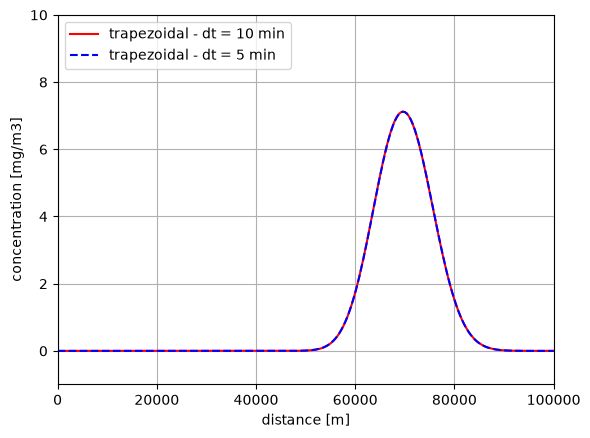

In [9]:
# Parameters for Task 2.1

# We do the first one for you!
dxmethod = 'central'
dtmethod = 'theta'

theta = 0.5

# replot the current result
plt.plot(x,c[N,:],'r',label='trapezoidal - dt = 10 min')

# reduce time step by factor 2
dt = dt / 2


# Now it's your turn! 

# number of time steps changes when dt is halved
N = int(round(Tend/dt))
N10 = int(round(Tend/(2*dt)))   # number of steps of the previous run (dt = 10 min)

# run Crank-Nicolson again with dt = 5 min
c_cn5 = advdiff(u,K,c0,lenD,dt,Tend,dxmethod,dtmethod,theta)
plt.plot(x,c_cn5[N,:],'b--',label='trapezoidal - dt = 5 min')

print(f"peak CN, dt = 10 min: {c[N10,:].max():.4f} mg/m3")
print(f"peak CN, dt =  5 min: {c_cn5[N,:].max():.4f} mg/m3")
print(f"max |difference|    : {np.max(np.abs(c_cn5[N,:]-c[N10,:])):.4f} mg/m3")


# finalize the plot. Hint: plot them together on the same figure
plt.axis(np.array([0,lenD,-1,10]))
plt.xlabel('distance [m]')
plt.ylabel('concentration [mg/m3]')
plt.legend(loc = "upper left")
plt.grid()


**Conclusion: Crank-Nicolson with $\Delta t = 10$ min vs. $\Delta t = 5$ min**

The two curves lie on top of each other. You cannot see a difference in the plot. The peak changes from 7.122 to 7.119 mg/m$^3$, and the largest difference anywhere in the domain is only about 0.016 mg/m$^3$ (0.2% of $c_0$).

So for Crank-Nicolson, a time step of 10 min is already small enough. Halving it does not change the result in a visible way, which means the error from the time integration is already negligible. The small difference that is left between the numerical peak (7.12) and the estimate from Task 1.1 (6.93) is therefore **not** caused by $\Delta t$. As explained in Task 1.3, it comes from the initial block on the grid being 10.4 km long instead of 10 km.

---

**Explicit and implicit Euler: halving the time step**

In the next cells we start from the last time step ($\Delta t = 5$ min) and keep halving it until two runs in a row give the same result.

We need a definition of "no discernible difference". We use: the largest difference between two runs in a row, $\max_x |c_{\Delta t} - c_{\Delta t/2}|$, is less than **0.1 mg/m$^3$**. That is 1% of $c_0$ and about the width of a line in a plot with a 0–10 mg/m$^3$ axis.

For each run we also measure the computation time (wall-clock time). This shows how much it costs to make each scheme accurate. The exact times depend on the computer.


Explicit Euler (theta = 0)
dt =   300.00 s ( 5.000 min) | peak = 8.2024 | cpu =   0.32 s
dt =   150.00 s ( 2.500 min) | peak = 7.6099 | max|diff| with previous = 0.5967 | cpu =   0.60 s
dt =    75.00 s ( 1.250 min) | peak = 7.3527 | max|diff| with previous = 0.2591 | cpu =   1.11 s
dt =    37.50 s ( 0.625 min) | peak = 7.2326 | max|diff| with previous = 0.1209 | cpu =   2.87 s
dt =    18.75 s ( 0.312 min) | peak = 7.1745 | max|diff| with previous = 0.0585 | cpu =   6.38 s
--> converged at dt = 18.75 s (0.312 min), total cpu time = 11.3 s


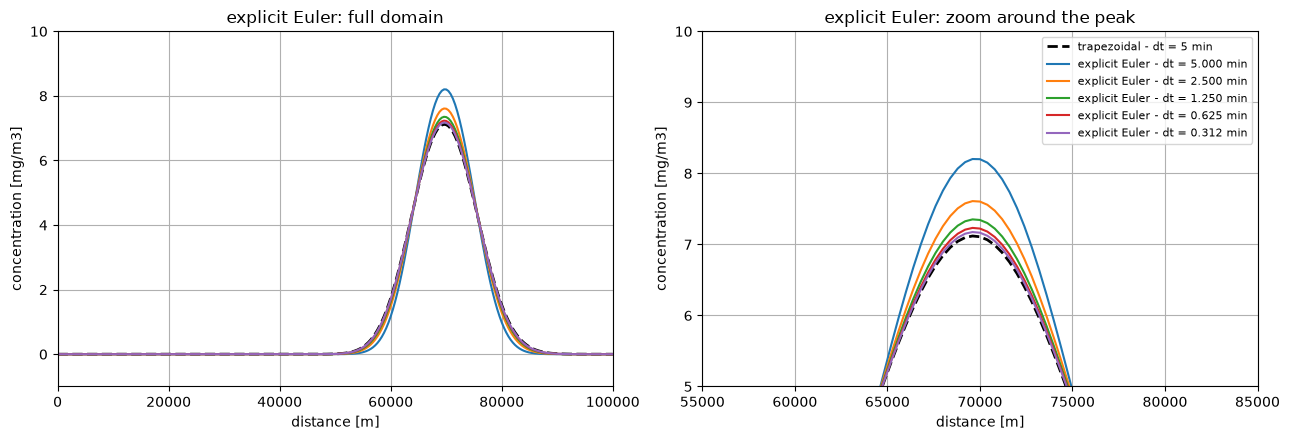

In [10]:
import time

dxmethod = 'central'
dtmethod = 'theta'
tol = 0.1                     # [mg/m3] "no discernible difference" between two successive runs

def run(theta, dt):
    """Run advdiff with time step dt and return the solution at t = Tend and the computation time."""
    t0 = time.perf_counter()
    c_all = advdiff(u, K, c0, lenD, dt, Tend, dxmethod, dtmethod, theta)
    elapsed = time.perf_counter() - t0
    return c_all[int(round(Tend/dt)), :], elapsed

def halve_until_converged(theta, dt_start, tol=tol, max_halvings=10):
    """Halve dt until two successive solutions differ less than tol. Returns a list of (dt, solution, time)."""
    results = []
    dt_i = dt_start
    sol, el = run(theta, dt_i)
    results.append((dt_i, sol, el))
    print(f"dt = {dt_i:8.2f} s ({dt_i/60:6.3f} min) | peak = {sol.max():.4f} | cpu = {el:6.2f} s")
    for _ in range(max_halvings):
        dt_i = dt_i / 2
        sol, el = run(theta, dt_i)
        results.append((dt_i, sol, el))
        diff = np.max(np.abs(results[-1][1] - results[-2][1]))
        print(f"dt = {dt_i:8.2f} s ({dt_i/60:6.3f} min) | peak = {sol.max():.4f} | "
              f"max|diff| with previous = {diff:.4f} | cpu = {el:6.2f} s")
        if diff < tol:
            break
    print(f"--> converged at dt = {dt_i:.2f} s ({dt_i/60:.3f} min), total cpu time = {sum(r[2] for r in results):.1f} s")
    return results

def plot_results(results, name):
    """Plot all runs of one scheme together with the Crank-Nicolson result (dt = 5 min) for comparison."""
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for a in ax:
        a.plot(x, c_cn5[int(round(Tend/300.)), :], 'k--', lw=2, label='trapezoidal - dt = 5 min')
        for dt_i, sol, _ in results:
            a.plot(x, sol, label=f'{name} - dt = {dt_i/60:.3f} min')
        a.set_xlabel('distance [m]')
        a.set_ylabel('concentration [mg/m3]')
        a.grid()
    ax[0].axis([0, lenD, -1, 10])
    ax[0].set_title(f'{name}: full domain')
    ax[1].axis([55000, 85000, 5, 10])
    ax[1].set_title(f'{name}: zoom around the peak')
    ax[1].legend(loc='upper right', fontsize=8)
    plt.tight_layout()
    plt.show()

# explicit (forward) Euler, starting from the last time step dt = 5 min
print("Explicit Euler (theta = 0)")
res_fe = halve_until_converged(0.0, dt)
plot_results(res_fe, 'explicit Euler')


Implicit Euler (theta = 1)
dt =   300.00 s ( 5.000 min) | peak = 6.3531 | cpu =   0.31 s
dt =   150.00 s ( 2.500 min) | peak = 6.7047 | max|diff| with previous = 0.3535 | cpu =   0.59 s
dt =    75.00 s ( 1.250 min) | peak = 6.9025 | max|diff| with previous = 0.1991 | cpu =   1.31 s
dt =    37.50 s ( 0.625 min) | peak = 7.0078 | max|diff| with previous = 0.1060 | cpu =   2.77 s
dt =    18.75 s ( 0.312 min) | peak = 7.0622 | max|diff| with previous = 0.0547 | cpu =   5.80 s
--> converged at dt = 18.75 s (0.312 min), total cpu time = 10.8 s


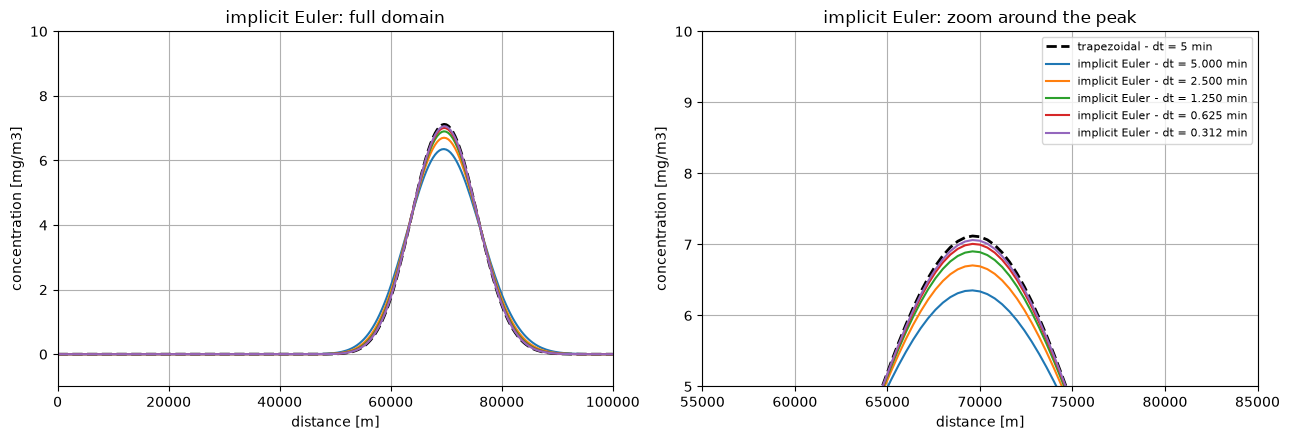

In [11]:
# implicit (backward) Euler, starting from the same time step dt = 5 min
print("Implicit Euler (theta = 1)")
res_be = halve_until_converged(1.0, dt)
plot_results(res_be, 'implicit Euler')


explicit Euler   : errors = [1.0924 0.4957 0.2366 0.1157 0.0572]  ->  error ratio per halving = [2.2  2.1  2.05 2.02]
implicit Euler   : errors = [0.7694 0.4158 0.2167 0.1107 0.0559]  ->  error ratio per halving = [1.85 1.92 1.96 1.98]
trapezoidal (CN) : errors = [0.0213 0.0053 0.0013 0.0003]  ->  error ratio per halving = [4.01 4.01 4.05]


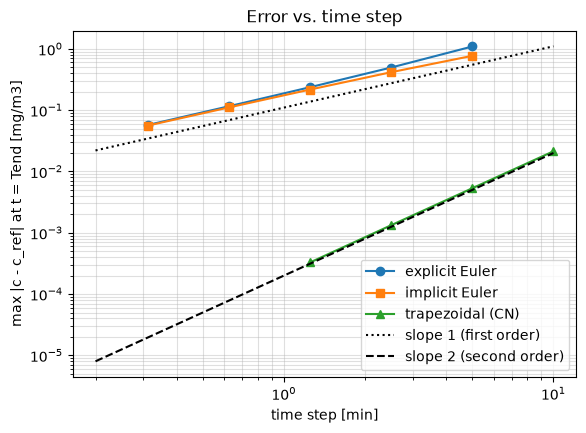

In [12]:
# Order of accuracy: error as a function of dt for the three schemes.
# As reference we use Crank-Nicolson with a very small time step (dt = 600/64 s), which is converged in time.
# All schemes use the same grid, so the spatial error is the same for all of them and drops out of the comparison.
c_ref, _ = run(0.5, 600./64)

res_cn = [(dt_i, *run(0.5, dt_i)) for dt_i in [600., 300., 150., 75.]]

plt.figure(figsize=(6.5, 4.5))
for res, name, mk in [(res_fe, 'explicit Euler', 'o-'), (res_be, 'implicit Euler', 's-'), (res_cn, 'trapezoidal (CN)', '^-')]:
    dts = np.array([r[0] for r in res])
    err = np.array([np.max(np.abs(r[1] - c_ref)) for r in res])
    plt.loglog(dts/60, err, mk, label=name)
    print(f"{name:17s}: errors = {np.round(err, 4)}  ->  error ratio per halving = {np.round(err[:-1]/err[1:], 2)}")
dd = np.array([0.2, 10])
plt.loglog(dd, 0.11*dd, 'k:', label='slope 1 (first order)')
plt.loglog(dd, 2e-4*dd**2, 'k--', label='slope 2 (second order)')
plt.xlabel('time step [min]')
plt.ylabel('max |c - c_ref| at t = Tend [mg/m3]')
plt.title('Error vs. time step')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()


**Conclusions Task 2.1**

Starting from $\Delta t = 5$ min, we halved $\Delta t$ until two runs in a row differed by less than 0.1 mg/m$^3$ (peaks in mg/m$^3$):

| scheme | peak, $\Delta t = 10$ min | converged at | peak, converged | error ratio per halving |
|---|---|---|---|---|
| trapezoidal ($\theta = 0.5$) | 7.12 | 10 min (already) | 7.12 | $\approx 4$ |
| explicit Euler ($\theta = 0$) | 9.66 (too high) | 18.75 s | 7.17 | $\approx 2$ |
| implicit Euler ($\theta = 1$) | 5.79 (too low) | 18.75 s | 7.06 | $\approx 2$ |

- **Order of accuracy.** Forward and backward Euler are first order, $\mathcal{O}(\Delta t)$: halving $\Delta t$ halves the error (slope 1 in the error plot). The trapezoidal rule is second order, $\mathcal{O}(\Delta t^2)$: halving $\Delta t$ divides the error by 4 (slope 2). That is why Crank-Nicolson is already accurate at 10 min, while the Euler schemes need a time step about 32 times smaller, and about 32 times more computation time.
- **Too high vs. too low.** The $\mathcal{O}(\Delta t)$ error of the Euler schemes acts as numerical diffusion, $K_{\text{eff}} = K \mp u^2\Delta t/2$. At $\Delta t = 10$ min this is $\mp 75$ m$^2$/s:
  - Explicit Euler: $K_{\text{eff}} = 25$ m$^2$/s, so too little diffusion and a peak that is too high.
  - Implicit Euler: $K_{\text{eff}} = 175$ m$^2$/s, so too much diffusion and a peak that is too low.

  With $\theta = 0.5$ the two contributions cancel.
- **Not instability.** Explicit Euler is stable in all runs ($d = K\Delta t/\Delta x^2 \le 0.375 \le 0.5$), so its error is an accuracy error.

**Conclusion:** the trapezoidal rule is the most accurate of the three, because it is second-order accurate in time and the two Euler schemes are only first order.

---
**Courant and mesh Péclet number**
$$\sigma = \frac{u\,\Delta t}{\Delta x}, \qquad Pe_{\Delta x} = \frac{u\,\Delta x}{K}$$
With $u = 0.5$ m/s, $K = 100$ m$^2$/s and $\Delta x = 400$ m, $Pe_{\Delta x} = 0.5\cdot400/100 = 2$ for every run. Only $\sigma$ changes with $\Delta t$:

| $\Delta t$ [s] | 600 | 300 | 150 | 75 | 37.5 | 18.75 |
|---|---|---|---|---|---|---|
| $\sigma$ | 0.75 | 0.375 | 0.1875 | 0.094 | 0.047 | 0.023 |
| $Pe_{\Delta x}$ | 2 | 2 | 2 | 2 | 2 | 2 |

(The reference run with $\Delta t = 9.375$ s has $\sigma = 0.012$.)


## Part III: effect of numerical diffusion

In this part of the assignment we will investigate the impact of numerical diffusion.
In general, there are two contributions to this numerical diffusion:
- the first order upwind scheme
- the $\theta$-method

To ensure that only numerical diffusion is at play, we set $K = 0$, so that there is no physical diffusion.
The other parameters of the previous runs in part I remain unchanged.

Since $K=0$, we solves the advection equation

$$
  \frac{\partial c}{\partial t} + v\,\frac{\partial c}{\partial x} = 0
$$

which represents the propagation of the substance in the river while the block shape remains unchanged throughout the journey.
In this way we can use this exact propagated solution for comparison with the obtained numerical solutions.

>**Task 3.1**
>
>Consider the same initial block-shaped profile of the cloud, with a maximum concentration of 10 mg/$m^{3}$ and a length of 10 km. Interpret the code below used to plot the cloud as it passes point B, 60 km downstream.
>


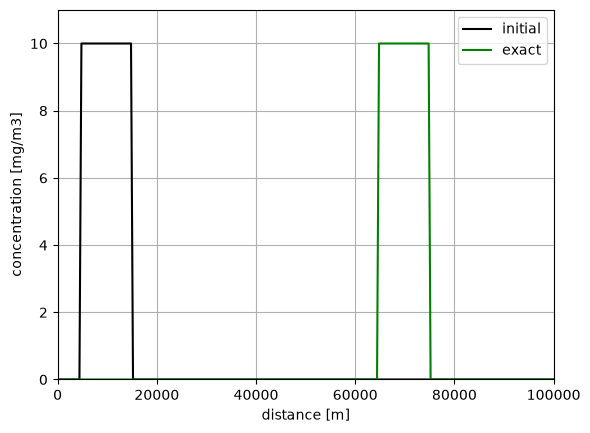

In [8]:
# true solution propagated

distance = 60000.
c1 = np.zeros(M)
c1[int(0.5 * lenC/dx + distance/dx):int(0.5 * lenC/dx + distance/dx) + int(lenC/dx) + 1] = 10.

plt.plot(x,c0,'k',label='initial')
plt.plot(x,c1,'g',label='exact')

# finalize the plot
plt.axis(np.array([0,100000,0,11]))
plt.xlabel('distance [m]')
plt.ylabel('concentration [mg/m3]')
plt.legend(loc = "upper right")
plt.grid()

**Answer Task 3.1**

**The code.** With $K = 0$ only advection is left, $\partial c/\partial t + u\,\partial c/\partial x = 0$, and its exact solution is $c(x,t) = c_0(x-ut)$. The block keeps its shape (height, length, sharp edges and mass) and only moves. The code builds this solution at B: `c1` is `c0` shifted by `distance/dx` $= 60\,000/400 = 150$ grid cells. The block moves from $x = 4.8$–$14.8$ km to $x = 64.8$–$74.8$ km, which takes $t = 60\,000/0.5 = 120\,000$ s. This green block is the reference for Task 3.2. Any change in shape in a numerical solution comes from the scheme, not from physics.

**What the numerical schemes do with the advection term.** The grid only has values $c_i$ every $\Delta x$, so $\partial c/\partial x$ has to be approximated with neighbouring points:
$$\text{upwind: } \frac{c_i - c_{i-1}}{\Delta x} \qquad\qquad \text{central: } \frac{c_{i+1} - c_{i-1}}{2\Delta x}$$

*Upwind smears (numerical diffusion).* A Taylor expansion gives
$$\frac{c_i - c_{i-1}}{\Delta x} = \frac{\partial c}{\partial x} - \frac{\Delta x}{2}\frac{\partial^2 c}{\partial x^2} + \dots$$
So the scheme actually solves $\partial c/\partial t + u\,\partial c/\partial x = K_{num}\,\partial^2 c/\partial x^2$ with
$$K_{num} = \frac{u\,\Delta x}{2} = \frac{0.5\cdot 400}{2} = 100\ \text{m}^2/\text{s}$$
Even with $K = 0$, the block gets rounded edges and a lower peak. The error is first order ($\propto \Delta x$).

*Central wiggles (numerical dispersion).* In $c_{i+1} - c_{i-1}$ the $\partial^2 c/\partial x^2$ terms cancel:
$$\frac{c_{i+1} - c_{i-1}}{2\Delta x} = \frac{\partial c}{\partial x} + \frac{\Delta x^2}{6}\frac{\partial^3 c}{\partial x^3} + \dots$$
So there is no numerical diffusion, and the scheme is second order. The leading error is a third derivative, which makes short waves travel at the wrong speed. The sharp edges of the block are made of short waves, so they drift apart and give oscillations: overshoot above 10 and negative values below 0.

| | upwind | central |
|---|---|---|
| points used | $i-1,\ i$ | $i-1,\ i+1$ |
| order | 1 | 2 |
| leading error | $\partial^2 c/\partial x^2$, numerical diffusion | $\partial^3 c/\partial x^3$, numerical dispersion |
| result | smooth, too wide and too low, $c \ge 0$ | correct height, wiggles, $c < 0$ possible |

In Part I the physical $K = 100$ m$^2$/s damped the wiggles of the central scheme ($Pe_{\Delta x} = 2$). With $K = 0$ nothing damps them, so they become visible in Task 3.2.

---
**Courant and mesh Péclet number**
$$\sigma = \frac{u\,\Delta t}{\Delta x}, \qquad Pe_{\Delta x} = \frac{u\,\Delta x}{K}$$
With $u = 0.5$ m/s, $K = 0$, $\Delta x = 400$ m and $\Delta t = 600$ s (the grid and time step of Task 3.2):
$$\sigma = \frac{0.5\cdot600}{400} = 0.75, \qquad Pe_{\Delta x} = \frac{0.5\cdot400}{0} = \infty$$
The exact solution itself does not depend on $\sigma$ or $Pe_{\Delta x}$.


>**Task 3.2**
>
>Use function `advdiff` to do the following three runs:
>- first order upwind and $\theta = 0$ (FTBS)
>- central differences and $\theta = 0.5$ (central + trapezoidal)
>- first order upwind and $\theta = 1.0$ (BTBS)
>
>For these runs, set $\Delta x = 400$ m, $\Delta t = 600$ s and $K = 0$ $m^{2}$/s.
>
>Include a graph containing the results of the three runs together with the analytical solution of **Task 3.1**. Clearly mark which curve belongs to which run.
>
>Answer the following questions in your report.
>1. Which of the schemes has the most numerical diffusion? Estimate the amount of this numerical diffusion.
>2. Which scheme has no numerical diffusion and why?
>3. Which of the two contributions to numerical diffusion has the largest impact?
>   - the first order upwind scheme or
>   - the implicit Euler method
>4. Which of the schemes gives a non-negative solution? And do you think this has any connection to the answer to question 2? Explain your reasoning.
>


FTBS (upwind, theta = 0)              : max =  9.663, min =  0.000 mg/m3
central + trapezoidal (theta = 0.5)   : max = 12.775, min = -2.575 mg/m3
BTBS (upwind, theta = 1)              : max =  5.786, min =  0.000 mg/m3


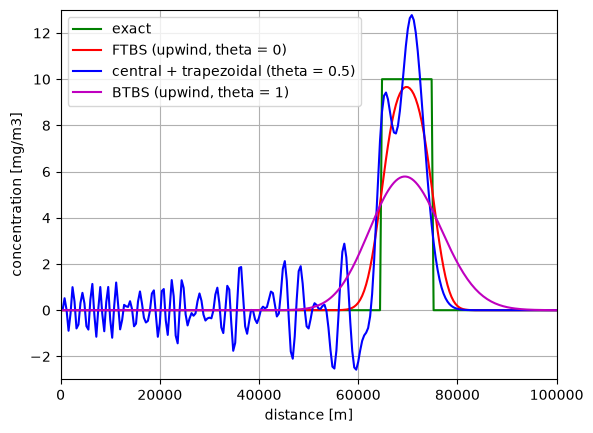

In [13]:
# parameters for Task 3.2
# we do the first one for you!

dtmethod = 'theta'
K = 0.

# plot true solution
plt.plot(x,c1,'g',label='exact')


# Now it's your turn!
u = 0.5
dx = 400.
dt = 600.                    # dt was changed in Task 2.1, so reset it to 10 min
Tend = 60000./u              # 120000 s: peak at B
N = int(round(Tend/dt))

runs = [('upwind',  0.0, 'r',   'FTBS (upwind, theta = 0)'),
        ('central', 0.5, 'b',   'central + trapezoidal (theta = 0.5)'),
        ('upwind',  1.0, 'm',   'BTBS (upwind, theta = 1)')]

for dxm, th, col, lab in runs:
    cr = advdiff(u, K, c0, lenD, dt, Tend, dxm, dtmethod, th)
    plt.plot(x, cr[N,:], col, label=lab)
    print(f"{lab:38s}: max = {cr[N,:].max():6.3f}, min = {cr[N,:].min():6.3f} mg/m3")

# plot the result
plt.axis(np.array([0,lenD,-3,13]))
plt.xlabel('distance [m]')
plt.ylabel('concentration [mg/m3]')
plt.legend(loc = "upper left")
plt.grid()

**Answer Task 3.2**

Run results at $t = 120\,000$ s (exact solution: block of 10 mg/m$^3$):

| run | max [mg/m$^3$] | min [mg/m$^3$] | $K_{num}$ [m$^2$/s] |
|---|---|---|---|
| FTBS (upwind, $\theta = 0$) | 9.66 | 0.00 | 25 |
| central + trapezoidal ($\theta = 0.5$) | 12.78 | −2.58 | 0 |
| BTBS (upwind, $\theta = 1$) | 5.79 | 0.00 | 175 |

The numerical diffusion follows from the modified equation. Upwind in space adds $+u\Delta x/2$ (Task 3.1), and the time integration adds $\mp u^2\Delta t/2$ (Task 2.1):
$$K_{num} = \underbrace{\frac{u\Delta x}{2}}_{\text{upwind}} \mp \underbrace{\frac{u^2\Delta t}{2}}_{\text{Euler}} = \frac{u\Delta x}{2}(1 \mp \sigma), \qquad \frac{u\Delta x}{2} = 100\ \text{m}^2/\text{s},\ \ \frac{u^2\Delta t}{2} = 75\ \text{m}^2/\text{s},\ \ \sigma = 0.75$$
As a check, fitting the observed peaks with the erf solution of Task 1.1 gives $K = 25$ and $K = 174$ m$^2$/s.

1. **Most numerical diffusion: BTBS.** Both contributions are positive and add up: $K_{num} = 100 + 75 = 175$ m$^2$/s. This is more than the physical $K = 100$ m$^2$/s of Part I. The peak drops from 10 to 5.8 mg/m$^3$.
2. **No numerical diffusion: central + trapezoidal.** In central differences the $\partial^2 c/\partial x^2$ terms cancel (Task 3.1). In Crank-Nicolson the $\mathcal{O}(\Delta t)$ terms of forward and backward Euler cancel (Task 2.1). Both schemes are second order, and their leading errors are dispersive, not diffusive.
3. **Largest contribution: the upwind scheme**, with $u\Delta x/2 = 100$ m$^2$/s against $u^2\Delta t/2 = 75$ m$^2$/s for implicit Euler. In general the time part is $\sigma$ times the space part, so upwind dominates as long as $\sigma < 1$. In FTBS the explicit Euler contribution is negative, $-75$, and it partly cancels the upwind diffusion: $100 - 75 = 25$ m$^2$/s.
4. **Non-negative: FTBS and BTBS.** Central + trapezoidal gives wiggles with $c_{\min} = -2.6$ and $c_{\max} = 12.8$ mg/m$^3$. Yes, this is connected to question 2. The scheme without numerical diffusion is the one that oscillates. Its dispersive error makes the short waves at the sharp edges travel at the wrong speed, and nothing damps them. The numerical diffusion of the upwind schemes damps exactly these short waves, so the solution stays smooth and positive, but it is smeared out. This is Godunov's theorem: a linear scheme that never creates new extrema (and therefore keeps $c \ge 0$) can be at most first-order accurate.

---
**Courant and mesh Péclet number**
$$\sigma = \frac{u\,\Delta t}{\Delta x}, \qquad Pe_{\Delta x} = \frac{u\,\Delta x}{K}$$
With $u = 0.5$ m/s, $K = 0$, $\Delta x = 400$ m and $\Delta t = 600$ s (the same for all three runs):
$$\sigma = \frac{0.5\cdot600}{400} = 0.75, \qquad Pe_{\Delta x} = \frac{0.5\cdot400}{0} = \infty$$


>**Task 3.3**
>
>Carry out two runs with the FTCS scheme:
>- without diffusion
>- with diffusion $K = 75$ $m^{2}$/s
>
>In both cases, set $u = 0.5$ m/s, $\Delta x = 400$ m and $\sigma = 0.75$.
>
>Make a graph showing the results without diffusion and with diffusion.
>Also make sure that the solution at *final time step* does not leave the domain. Clearly mark the curves.
>
>What is the mesh P&eacute;clet number?
>
>Explain your findings.


mesh Peclet number =  2.6666666666666665


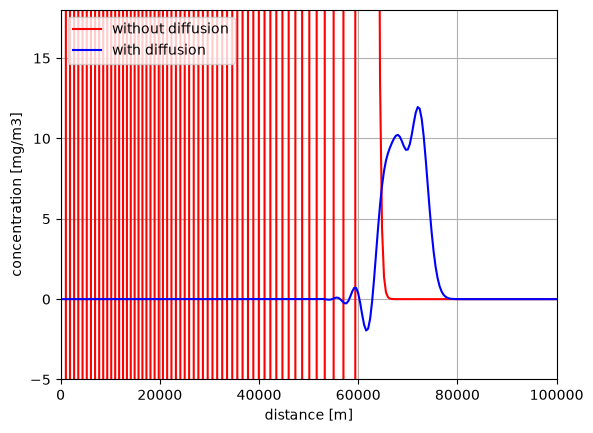

In [14]:
# parameters for Task 3.3

u = 0.5
K = 75.
dx = 400.
sigma = 0.75
distance=60000.

# compute the end time and time step
Tend = np.ceil(distance/u)
dt = np.floor(sigma * dx / u)
N = int(Tend/dt)

# solve the advection-diffusion equation using the FTCS scheme
# without diffusion

c = advdiff(u,0.,c0,lenD,dt,Tend,'central','theta',0.)
plt.plot(x,c[N,:],'r',label='without diffusion')

# with diffusion

c = advdiff(u,K,c0,lenD,dt,Tend,'central','theta',0.)
plt.plot(x,c[N,:],'b',label='with diffusion')
print('mesh Peclet number = ',u*dx/K)

# finalize the plot
plt.axis(np.array([0,lenD,-5,18]))
plt.xlabel('distance [m]')
plt.ylabel('concentration [mg/m3]')
plt.legend(loc = "upper left")
plt.grid()

**Answer Task 3.3**

Parameters: $\Delta t = \sigma\Delta x/u = 600$ s, $t_{end} = 120\,000$ s ($N = 200$). At $t_{end}$ the cloud is centred at $x \approx 70$ km, so it stays inside the 100 km domain.

**Mesh Péclet number** (with diffusion):
$$Pe_{\Delta x} = \frac{u\Delta x}{K} = \frac{0.5\cdot 400}{75} = 2.67$$
Without diffusion, $Pe_{\Delta x} = \infty$.

**Without diffusion: unstable.** The solution blows up to about $10^{19}$ mg/m$^3$, so the whole domain fills with oscillations outside the plot. FTCS is stable only if $d = K\Delta t/\Delta x^2 \le 1/2$ and $\sigma^2 \le 2d$. For $K = 0$ we have $d = 0$, so $\sigma^2 = 0.56 > 0$, and FTCS is unstable for every $\Delta t$ (unconditionally unstable for pure advection). The reason is the negative numerical diffusion of explicit Euler, $-u^2\Delta t/2 = -75$ m$^2$/s (Task 2.1). With nothing to balance it, every short wave grows each time step.

**With diffusion $K = 75$ m$^2$/s: stable, but with wiggles.** The solution stays bounded (max 11.95 and min −1.95 mg/m$^3$), but it oscillates around the block.
- **Stable:** $d = 75\cdot600/400^2 = 0.28$, so $2d = 0.5625 = \sigma^2$. This is exactly the stability limit. $K = 75$ is exactly the value that cancels the negative numerical diffusion of explicit Euler, so $K_{\text{eff}} = K - u^2\Delta t/2 = 0$.
- **Wiggles:** $K_{\text{eff}} = 0$ means nothing is left to damp the dispersion error of the central scheme. In the same way, $Pe_{\Delta x} = 2.67 > 2$, so the central scheme is no longer free of oscillations. The result looks like the central + trapezoidal run of Task 3.2: the shape is correct, but there are overshoot and negative concentrations.

**Conclusion:** physical diffusion is needed to make FTCS stable. It must be at least $u^2\Delta t/2$, which follows from $\sigma^2 \le 2d$. Avoiding wiggles needs even more diffusion: $Pe_{\Delta x} \le 2$, so $K \ge u\Delta x/2 = 100$ m$^2$/s.

---
**Courant and mesh Péclet number**
$$\sigma = \frac{u\,\Delta t}{\Delta x}, \qquad Pe_{\Delta x} = \frac{u\,\Delta x}{K}$$
| run | $u$ [m/s] | $K$ [m$^2$/s] | $\Delta x$ [m] | $\Delta t$ [s] | $\sigma$ | $Pe_{\Delta x}$ |
|---|---|---|---|---|---|---|
| FTCS without diffusion | 0.5 | 0 | 400 | 600 | 0.75 | $\infty$ |
| FTCS with diffusion | 0.5 | 75 | 400 | 600 | 0.75 | 2.67 |


## Part IV: numerical stability

In this part of the assignment we will explore the stability of the various schemes.

>**Task 4.1**
>
>We study the stability (and accuracy) of the following three schemes:
>- the FTCS scheme,
>- the FTBS scheme, and
>- Crank-Nicolson with central differences.
>
>Do the following:
>
>1. Try to find the maximum time step for each scheme such that the solution is about to be stable.
>2. Plot the stable solution of the given scheme in a graph and write down the time step you found. You will need these results later for the stability analysis.
>
>Use the parameters from the last run in the previous question, except $K = 125$ $m^{2}$/s.
>
>
>1. Which of the schemes is/are unconditionally stable? 
>2. Which of the schemes is the most accurate one? Why?
>3. Which of the numerical solutions has the largest maximum? Why?
>


maximum time step =  640.0
maximum time step FTBS =  355.0
FTCS            : max = 8.873, min = 0.000 mg/m3
FTBS            : max = 5.701, min = 0.000 mg/m3
CN, dt = 640 s  : max = 6.588, min = 0.000 mg/m3
CN, dt = 6000 s : max = 6.538, min = -0.711 mg/m3


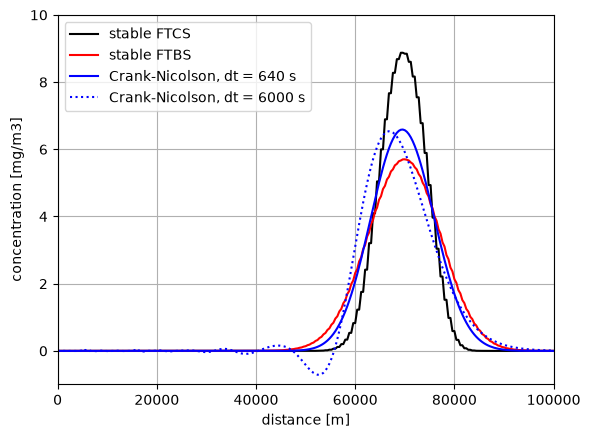

In [15]:
# time step based on stability of FTCS
K = 125.
dt2 = np.floor(0.5 * dx*dx / K)

print('maximum time step = ',dt2)
ce = advdiff(u,K,c0,lenD,dt2,Tend,'central','theta',0.)
N2 = int(Tend/dt2)
plt.plot(x,ce[N2,:],'k',label='stable FTCS')

# time step based on stability of FTBS: sigma + 2d <= 1  ->  dt <= 1/(u/dx + 2K/dx^2)
dt3 = np.floor(1. / (u/dx + 2.*K/dx**2))

print('maximum time step FTBS = ',dt3)
cu = advdiff(u,K,c0,lenD,dt3,Tend,'upwind','theta',0.)
N3 = int(Tend/dt3)
plt.plot(x,cu[N3,:],'r',label='stable FTBS')

# time step based on stability of trapezoidal rule/central differences:
# unconditionally stable, so there is no maximum time step.
# We use the same dt as FTCS for a fair comparison, plus a very large dt to show it stays stable.
dt4 = dt2
cc = advdiff(u,K,c0,lenD,dt4,Tend,'central','theta',0.5)
N4 = int(Tend/dt4)
plt.plot(x,cc[N4,:],'b',label='Crank-Nicolson, dt = %d s' % dt4)

dt5 = 6000.
cc5 = advdiff(u,K,c0,lenD,dt5,Tend,'central','theta',0.5)
N5 = int(Tend/dt5)
plt.plot(x,cc5[N5,:],'b:',label='Crank-Nicolson, dt = %d s' % dt5)

for name, sol in [('FTCS', ce[N2,:]), ('FTBS', cu[N3,:]), ('CN, dt = %d s' % dt4, cc[N4,:]), ('CN, dt = %d s' % dt5, cc5[N5,:])]:
    print(f"{name:16s}: max = {sol.max():.3f}, min = {sol.min():.3f} mg/m3")

# finalize the plot
plt.axis(np.array([0,lenD,-1,10]))
plt.xlabel('distance [m]')
plt.ylabel('concentration [mg/m3]')
plt.legend(loc = "upper left")
plt.grid()

**Answer Task 4.1**

Parameters: $u = 0.5$ m/s, $K = 125$ m$^2$/s, $\Delta x = 400$ m, $t_{end} = 120\,000$ s. We use the diffusion number $d = K\Delta t/\Delta x^2$.

**Maximum stable time steps**

| scheme | stability condition | $\Delta t_{\max}$ | check |
|---|---|---|---|
| FTCS | $d \le \tfrac12$ and $\sigma^2 \le 2d$, so $\Delta t \le \dfrac{\Delta x^2}{2K} = 640$ s (the second condition gives $\Delta t \le 2K/u^2 = 1000$ s, so it is not the binding one) | **640 s** | at 650 s it blows up |
| FTBS | $\sigma + 2d \le 1$, so $\Delta t \le \dfrac{1}{u/\Delta x + 2K/\Delta x^2} = 355.6$ s | **355 s** | at 360 s it blows up |
| Crank-Nicolson | none (unconditionally stable) | **no maximum** | stable even at 6000 s and 40 000 s |

The run results:

| scheme | $\Delta t$ [s] | max [mg/m$^3$] | $K_{\text{eff}}$ [m$^2$/s] |
|---|---|---|---|
| FTCS | 640 | 8.87 | $K - u^2\Delta t/2 = 125 - 80 = 45$ |
| FTBS | 355 | 5.70 | $K + \tfrac{u\Delta x}{2}(1-\sigma) = 125 + 55.6 = 180.6$ |
| Crank-Nicolson | 640 | 6.59 | $K = 125$ |
| exact ($L_c = 10.4$ km) | – | 6.58 | 125 |

Putting each $K_{\text{eff}}$ into $c_{\max} = c_0\,\text{erf}\!\left(L_c/4\sqrt{K_{\text{eff}}t}\right)$ reproduces the observed peaks (8.87, 5.70 and 6.58).

1. **Unconditionally stable:** only Crank-Nicolson. FTCS and FTBS are explicit and have a maximum time step. Crank-Nicolson with $\Delta t = 6000$ s ($\sigma = 7.5$) does not blow up. It does get inaccurate, though, with small wiggles down to −0.7 mg/m$^3$. Stability does not guarantee accuracy.
2. **Most accurate: Crank-Nicolson.** Its peak of 6.59 is almost the exact 6.58 mg/m$^3$. It is second order in time and in space, so it has no numerical diffusion ($K_{\text{eff}} = K$). FTCS is first order in time, and FTBS is first order in time and in space. Their $\mathcal{O}(\Delta t)$ and $\mathcal{O}(\Delta x)$ errors act as extra (negative or positive) diffusion.
3. **Largest maximum: FTCS (8.87 mg/m$^3$).** Explicit Euler adds negative numerical diffusion of $-u^2\Delta t/2 = -80$ m$^2$/s, so the cloud spreads as if $K = 45$ m$^2$/s instead of 125 m$^2$/s. FTBS has the lowest maximum, because upwind adds more positive diffusion than explicit Euler removes ($K_{\text{eff}} = 180.6$ m$^2$/s).

---
**Courant and mesh Péclet number**
$$\sigma = \frac{u\,\Delta t}{\Delta x}, \qquad Pe_{\Delta x} = \frac{u\,\Delta x}{K}, \qquad d = \frac{K\,\Delta t}{\Delta x^2}$$

| run | $\Delta t$ [s] | $\sigma$ | $Pe_{\Delta x}$ | $d$ |
|---|---|---|---|---|
| FTCS | 640 | 0.80 | 1.6 | 0.50 |
| FTBS | 355 | 0.44 | 1.6 | 0.28 |
| Crank-Nicolson | 640 | 0.80 | 1.6 | 0.50 |
| Crank-Nicolson | 6000 | 7.5 | 1.6 | 4.69 |

$Pe_{\Delta x} = 0.5\cdot400/125 = 1.6 \le 2$ for all runs, so the central schemes have no spatial wiggles at small $\Delta t$.


> By Marcel Zijlema, Delft University of Technology. CC BY 4.0, more info [on the Credits page of Workbook](https://mude.citg.tudelft.nl/workbook-2026/credits.html).